# 02 — Model evaluation and explainability

This notebook inspects artifacts produced by `uv run credit-risk all`. Model and threshold selection use validation data only; the test set is a one-shot final evaluation.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
REPORTS = ROOT / 'reports'
metrics_path = REPORTS / 'model_metrics.json'
if not metrics_path.exists():
    raise FileNotFoundError('Run `uv run credit-risk all` from the repository root first.')
metrics = json.loads(metrics_path.read_text())
metrics['selection']

{'model_metric': 'validation PR-AUC',
 'selected_model': 'xgboost',
 'threshold_rule': 'minimum validation cost with false-negative:false-positive = 5:1',
 'selected_threshold': 0.39}

In [2]:
comparison = pd.DataFrame(metrics['test_metrics']).T
comparison[['pr_auc', 'roc_auc', 'brier_score']]

,pr_auc,roc_auc,brier_score
logistic_regression,0.502946,0.720568,0.20646
xgboost,0.558779,0.786856,0.174678


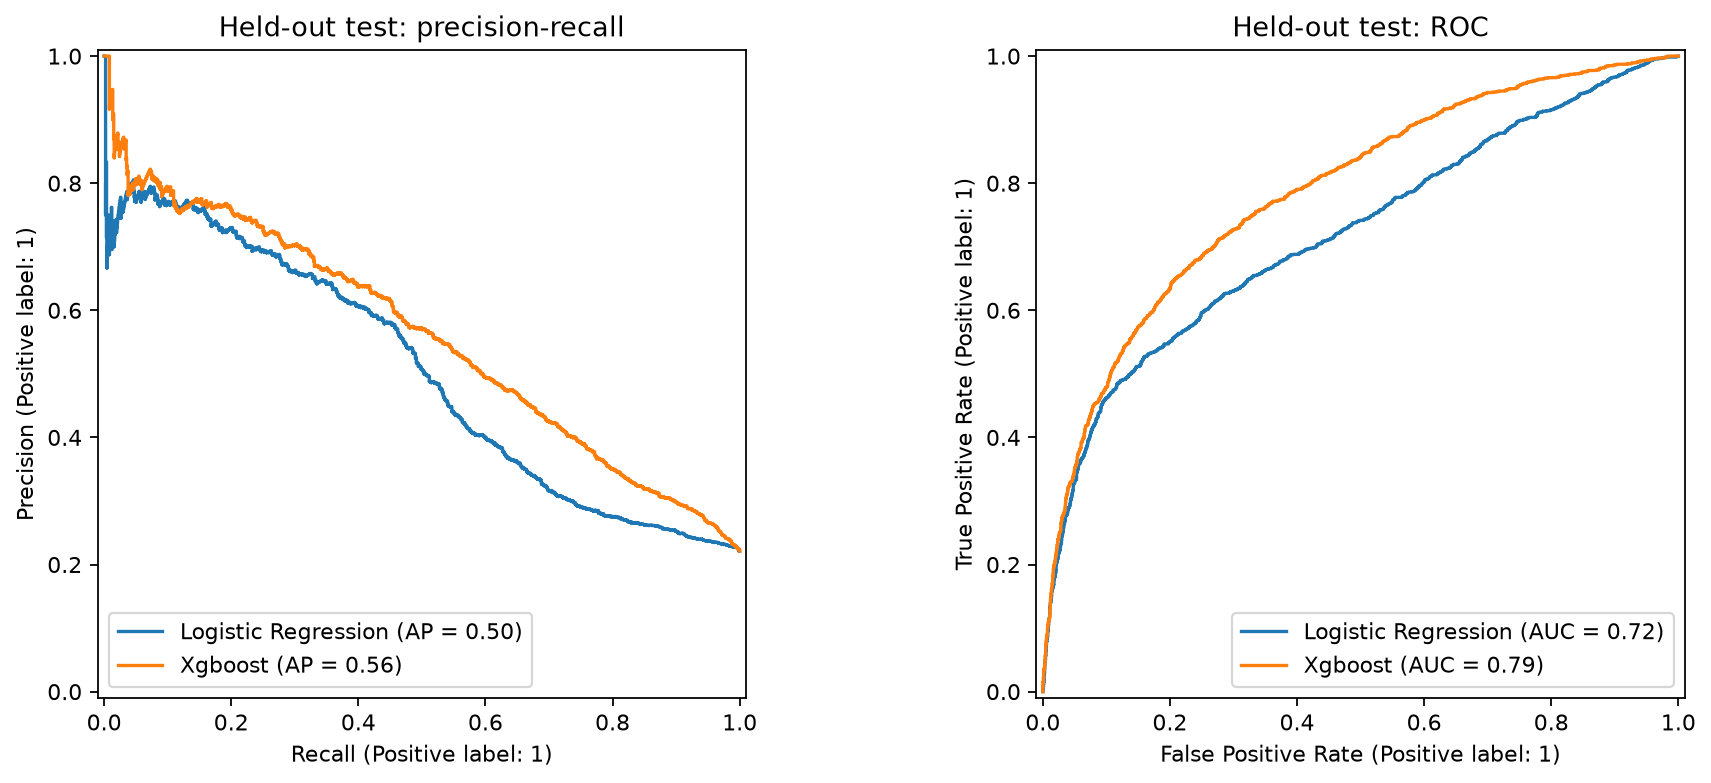

In [3]:
display(Image(filename=str(REPORTS / 'figures' / 'model_comparison.png')))

In [4]:
predictions = pd.read_csv(REPORTS / 'test_predictions.csv')
rows = []
for threshold in [0.30, metrics['selection']['selected_threshold'], 0.50, 0.70]:
    prediction = (predictions['predicted_probability'] >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(predictions['actual_default'], prediction, labels=[0, 1]).ravel()
    rows.append({
        'threshold': threshold,
        'precision': precision_score(predictions['actual_default'], prediction, zero_division=0),
        'recall': recall_score(predictions['actual_default'], prediction, zero_division=0),
        'f1': f1_score(predictions['actual_default'], prediction, zero_division=0),
        'false_positives': fp,
        'false_negatives': fn,
    })
pd.DataFrame(rows).drop_duplicates('threshold')

,threshold,precision,recall,f1,false_positives,false_negatives
0,0.30,0.314708,0.865863,0.461631,2502,178
1,0.39,0.380970,0.763376,0.508279,1646,314
2,0.50,0.476326,0.629239,0.542208,918,492
3,0.70,0.627385,0.421251,0.504058,332,768


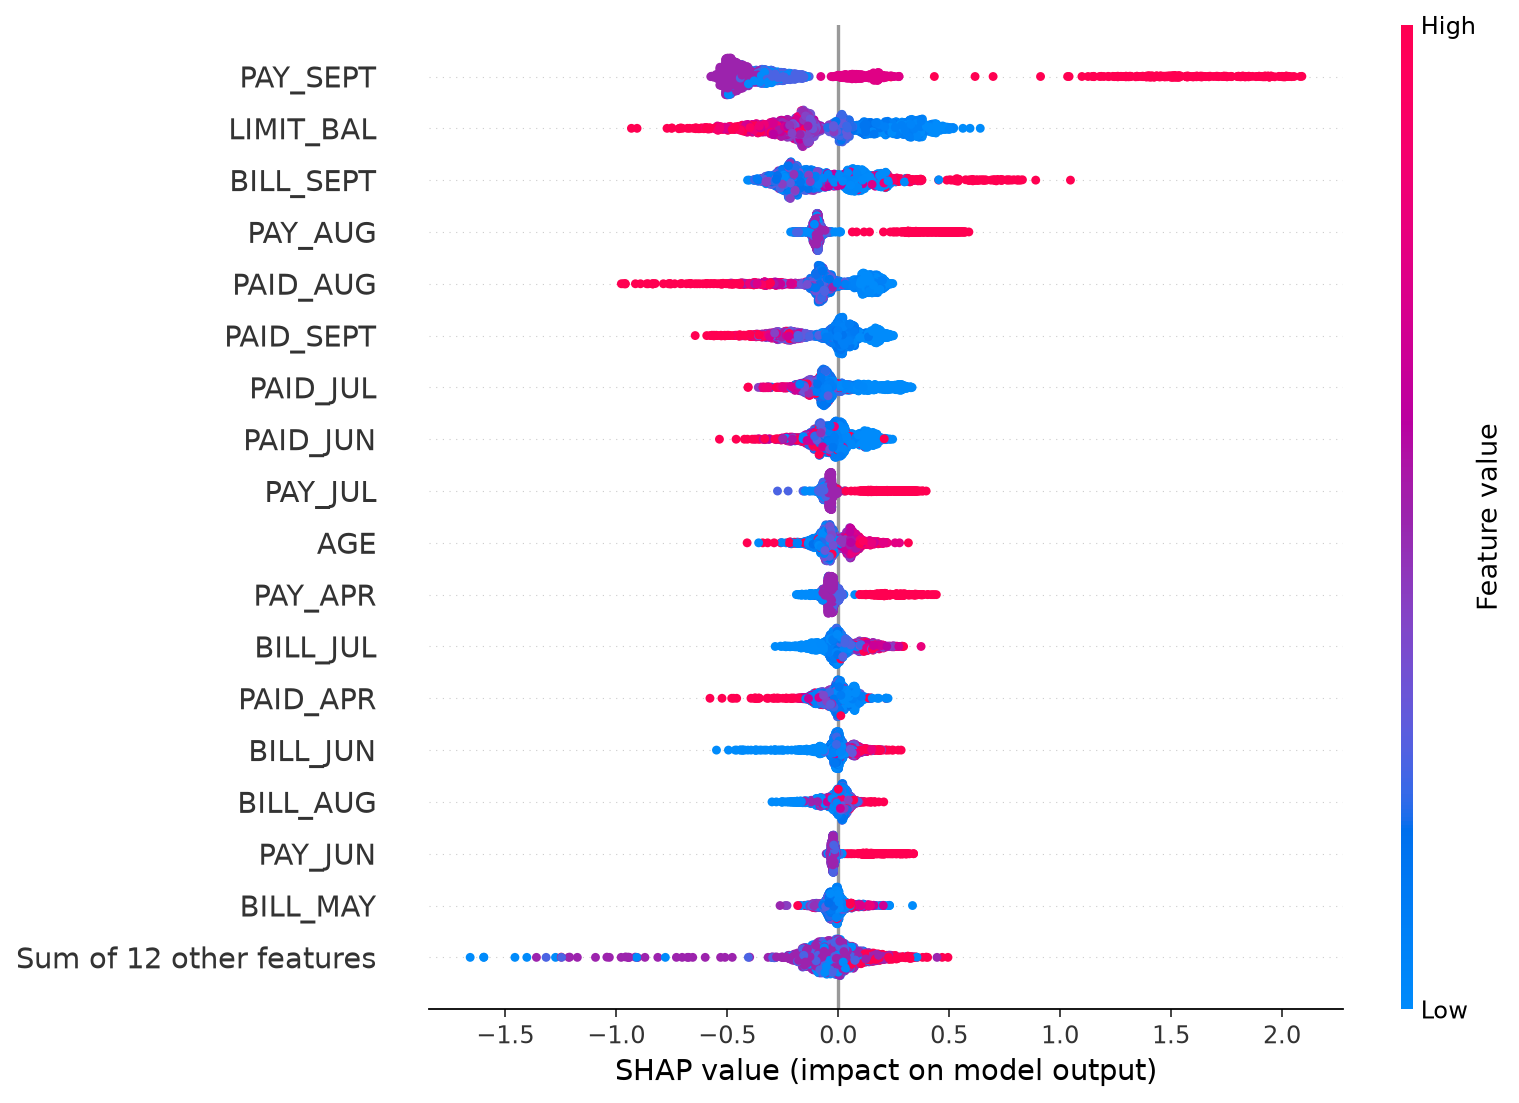

,feature,mean_abs_shap
0,PAY_SEPT,0.490008
1,LIMIT_BAL,0.228952
2,BILL_SEPT,0.171250
3,PAY_AUG,0.140647
4,PAID_AUG,0.138404
5,PAID_SEPT,0.122224
6,PAID_JUL,0.108679
7,PAID_JUN,0.080074
8,PAY_JUL,0.070125
9,AGE,0.065017


In [5]:
display(Image(filename=str(REPORTS / 'figures' / 'shap_summary.png')))
pd.read_csv(REPORTS / 'shap_importance.csv').head(15)

In [6]:
for grouping in ['sex', 'age', 'education']:
    print(f'\nAudit by {grouping}')
    display(pd.read_csv(REPORTS / f'fairness_by_{grouping}.csv'))


Audit by sex


,group,n,observed_default_rate,predicted_positive_rate,mean_predicted_risk,true_positive_rate,false_positive_rate,precision
0,Female,3645,0.208505,0.398628,0.392195,0.723684,0.312998,0.378527
1,Male,2355,0.240764,0.512102,0.444594,0.816578,0.415548,0.383914



Audit by age


,group,n,observed_default_rate,predicted_positive_rate,mean_predicted_risk,true_positive_rate,false_positive_rate,precision
0,30-39,2222,0.200720,0.391989,0.385109,0.748879,0.302365,0.383467
1,40-49,1283,0.226812,0.492595,0.427616,0.762887,0.413306,0.351266
2,50-59,487,0.240246,0.492813,0.447715,0.769231,0.405405,0.375000
3,60+,72,0.347222,0.555556,0.475572,0.840000,0.404255,0.525000
4,<30,1936,0.231405,0.452479,0.423527,0.772321,0.356183,0.394977



Audit by education


,group,n,observed_default_rate,predicted_positive_rate,mean_predicted_risk,true_positive_rate,false_positive_rate,precision
0,Graduate school,2082,0.189241,0.370317,0.372869,0.725888,0.287322,0.370947
1,High school,991,0.256307,0.539859,0.467749,0.811024,0.446404,0.385047
2,Other/unknown,93,0.053763,0.053763,0.166115,0.200000,0.045455,0.200000
3,University,2834,0.237826,0.475653,0.430935,0.771513,0.383333,0.385757


## Interpretation guardrails

The threshold cost is illustrative, SHAP attributions are not causal, and the group tables are descriptive rather than proof of fairness. Inspecting alternate thresholds on the final test set is educational only; choosing a new threshold from these results would contaminate the test set.

The final split keeps identical feature profiles together. PR-AUC here means average precision. The constant training-prevalence baseline has a better Brier score than either weighted model: ranking gains do not establish calibrated default probabilities.